In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from torch.utils.data import TensorDataset, DataLoader, random_split

In [3]:
df_r=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\3DatasetsCombined.csv")
df_p=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\combined_processed_v1.csv")

In [12]:
#CNN V1 baseline model training 
#text prep
# RAW dataset
df_r = df_r.dropna(subset=['text'])
df_r['text'] = df_r['text'].astype(str)

texts_r = df_r['text']
labels_r = df_r['class']

In [13]:
#CNN V1 baseline model training 
#text prep
# CLEAN dataset
df_p = df_p.dropna(subset=['clean_text'])
df_p['clean_text'] = df_p['clean_text'].astype(str)

texts_p = df_p['clean_text']
labels_p = df_p['class']

In [14]:
tokenizer_r = Tokenizer(num_words=10000)
tokenizer_r.fit_on_texts(texts_r)

X_r = pad_sequences(tokenizer_r.texts_to_sequences(texts_r), maxlen=100)
y_r = labels_r.values

In [15]:
tokenizer_p = Tokenizer(num_words=10000)
tokenizer_p.fit_on_texts(texts_p)

X_p = pad_sequences(tokenizer_p.texts_to_sequences(texts_p), maxlen=100)
y_p = labels_p.values

In [16]:
df_r = df_r.reset_index(drop=True)

Xr_train, Xr_test, yr_train, yr_test, idxr_train, idxr_test = train_test_split(
    X_r, y_r, df_r.index,
    test_size=0.2,
    random_state=42,
    stratify=y_r
)

In [17]:
df_p = df_p.reset_index(drop=True)

Xp_train, Xp_test, yp_train, yp_test, idxp_train, idxp_test = train_test_split(
    X_p, y_p, df_p.index,
    test_size=0.2,
    random_state=42,
    stratify=y_p
)

In [18]:
classes_p = np.unique(yp_train)
weights_p = compute_class_weight('balanced', classes=classes_p, y=yp_train)
class_weight_p = dict(zip(classes_p, weights_p))

In [19]:
model_r = Sequential([
    Embedding(10000, 64, input_length=100),

    Conv1D(128, 5, activation='relu'),
    Dropout(0.3),

    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),

    Dense(64, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

model_r.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

c:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\venv\Lib\site-packages\keras\src\layers\core\embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [20]:
model_p = Sequential([
    Embedding(10000, 64, input_length=100),

    Conv1D(128, 5, activation='relu'),
    Dropout(0.3),

    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),

    Dense(64, activation='relu'),
    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

model_p.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [22]:
history_r = model_r.fit(
    Xr_train,
    yr_train,
    epochs=8,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 67s 62ms/step - accuracy: 0.9894 - loss: 0.0337 - val_accuracy: 0.8647 - val_loss: 0.8785
Epoch 2/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.9906 - loss: 0.0299 - val_accuracy: 0.8647 - val_loss: 0.8531
Epoch 3/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9910 - loss: 0.0284 - val_accuracy: 0.8616 - val_loss: 1.0324
Epoch 4/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9927 - loss: 0.0227 - val_accuracy: 0.8564 - val_loss: 1.0486
Epoch 5/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 55s 51ms/step - accuracy: 0.9926 - loss: 0.0226 - val_accuracy: 0.8574 - val_loss: 1.0966
Epoch 6/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 54s 49ms/step - accuracy: 0.9938 - loss: 0.0189 - val_accuracy: 0.8629 - val_loss: 1.2313
Epoch 7/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 59s 54ms/step - accuracy: 0.9937 - loss: 0.0186 - val_accuracy: 0.8582 - val_loss: 1.5780
Epoch 8/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 60s 55ms/step - accuracy: 0.9933 - loss: 0

In [25]:
history_p = model_p.fit(
    Xp_train,
    yp_train,
    epochs=8,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weight_p
)

Epoch 1/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 62s 50ms/step - accuracy: 0.8388 - loss: 0.3564 - val_accuracy: 0.8824 - val_loss: 0.2831
Epoch 2/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.8982 - loss: 0.2540 - val_accuracy: 0.8775 - val_loss: 0.2874
Epoch 3/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9270 - loss: 0.1854 - val_accuracy: 0.8751 - val_loss: 0.3303
Epoch 4/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9508 - loss: 0.1320 - val_accuracy: 0.8681 - val_loss: 0.4014
Epoch 5/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 55s 51ms/step - accuracy: 0.9673 - loss: 0.0891 - val_accuracy: 0.8647 - val_loss: 0.5920
Epoch 6/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9760 - loss: 0.0688 - val_accuracy: 0.8621 - val_loss: 0.5848
Epoch 7/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 53s 49ms/step - accuracy: 0.9816 - loss: 0.0548 - val_accuracy: 0.8611 - val_loss: 0.8092
Epoch 8/8
1081/1081 ━━━━━━━━━━━━━━━━━━━━ 52s 48ms/step - accuracy: 0.9850 - loss: 0

In [26]:
pred_probs_r = model_r.predict(Xr_test)
preds_r = (pred_probs_r > 0.5).astype(int)

301/301 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


In [27]:
pred_probs_p = model_p.predict(Xp_test)
preds_p = (pred_probs_p > 0.5).astype(int)

301/301 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


In [28]:
print("RAW DATA RESULTS")
print("Accuracy:", accuracy_score(yr_test, preds_r))
print("Precision:", precision_score(yr_test, preds_r))
print("Recall:", recall_score(yr_test, preds_r))
print("F1:", f1_score(yr_test, preds_r))

RAW DATA RESULTS
Accuracy: 0.8513007284079084
Precision: 0.8798599594619495
Recall: 0.860050432276657
F1: 0.8698424264504964


In [29]:
print("\nCLEAN DATA RESULTS")
print("Accuracy:", accuracy_score(yp_test, preds_p))
print("Precision:", precision_score(yp_test, preds_p))
print("Recall:", recall_score(yp_test, preds_p))
print("F1:", f1_score(yp_test, preds_p))


CLEAN DATA RESULTS
Accuracy: 0.8478351373855121
Precision: 0.864657631954351
Recall: 0.8733789625360231
F1: 0.8689964157706093


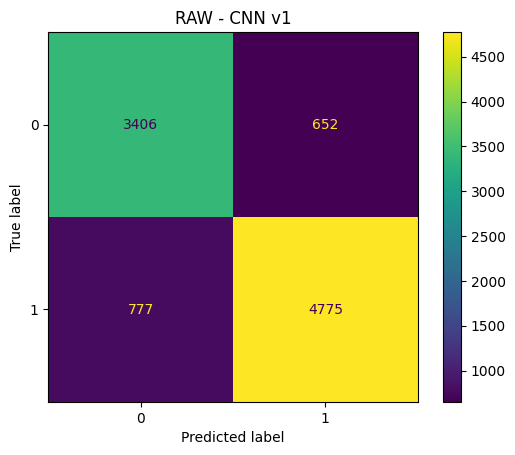

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_r = confusion_matrix(yr_test, preds_r)
ConfusionMatrixDisplay(cm_r).plot()
plt.title("RAW - CNN v1")
plt.show()

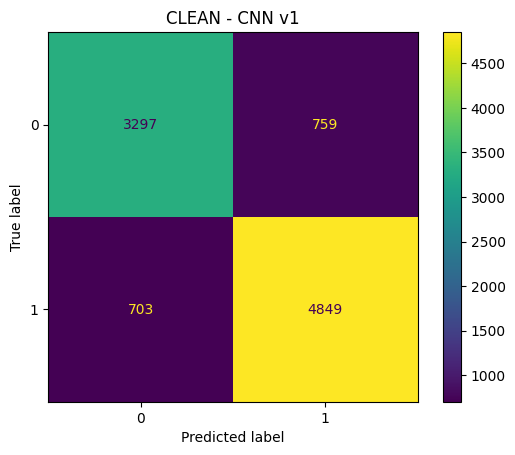

In [31]:
cm_p = confusion_matrix(yp_test, preds_p)
ConfusionMatrixDisplay(cm_p).plot()
plt.title("CLEAN - CNN v1")
plt.show()

In [32]:
wrong_r = np.where(preds_r.flatten() != yr_test)[0]
wrong_idx_r = idxr_test[wrong_r]

for i in range(10):
    idx = wrong_idx_r[i]
    print("TEXT:", df_r.loc[idx, 'text'])
    print("TRUE:", df_r.loc[idx, 'class'])
    print("PRED:", preds_r.flatten()[wrong_r[i]])
    print("-"*50)

TEXT: "you are HOT!!!\xa0\xa0 Damn!"
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: &#8220;@AdderallHadMe: Adderall had me killing two birds with one stone http://t.co/wMiNpN64m2&#8221;&#128128;
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: " momma said no pussy cats inside my doghouse "
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: Nuland's Nazis, I didn't know that the Muslims were working for Nuland.
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: RT @Racheldoesstuff: "You gotta have luuuuube/All ya really need is luuuube!"- Dental Dam Yankees
TRUE: 1
PRED: 0
--------------------------------------------------
TEXT: "CostaY, what shit u talking man ?"
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: Awwww, now I want some of those prawn cakes.. and I m not even a fan of prawns haha #MKR
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT

In [33]:
wrong_p = np.where(preds_p.flatten() != yp_test)[0]
wrong_idx_p = idxp_test[wrong_p]

for i in range(10):
    idx = wrong_idx_p[i]
    print("TEXT:", df_p.loc[idx, 'clean_text'])
    print("TRUE:", df_p.loc[idx, 'class'])
    print("PRED:", preds_p.flatten()[wrong_p[i]])
    print("-"*50)

TEXT: rt pat martin is gon na show some yankee a thing or two at the james beard house tonight
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: rt on this armisticeday the cry never again is absent and mock our pledge to neverforget the fallen from ancient an8230
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: lookdumbfuck i am just pointing out the asshoies hypocrisy in calling out other people error if you want to defend him and suckhiscock then go get a private room together and have some decency
TRUE: 1
PRED: 0
--------------------------------------------------
TEXT: a lot of money so u can sit on your as
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: white people need those weapon to defend themselves from the subhuman trash your sort unleashes on u
TRUE: 0
PRED: 1
--------------------------------------------------
TEXT: choudary tell the truth about islam islam ha no spirituality it is only about forcing t

In [34]:
#testing on real data samples
#Step 1: load datasets and get basic info
df_1=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv')
df_2=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv')

In [35]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()

def full_preprocess(text):
    text = str(text).lower()
    
    # Step 2: remove URLs, mentions, keep hashtag words
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    
    # Step 3: normalize elongated words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Step 4: remove punctuation + extra spaces
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    
    # Step 5: lemmatization
    tokens = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(word) for word in tokens])
    
    return text

In [36]:
df_1 = df_1.rename(columns={'tweet': 'text'})
df_1['label'] = df_1['class'].apply(lambda x: 0 if x == 2 else 1)

# preprocessed
df_1['clean_text'] = df_1['text'].apply(full_preprocess)

In [37]:
df_2 = df_2.rename(columns={'tweet': 'text'})

# preprocessed
df_2['clean_text'] = df_2['text'].apply(full_preprocess)

In [38]:
# RAW model inputs
X1_raw_r = pad_sequences(tokenizer_r.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_1['clean_text']), maxlen=100)

# CLEAN model inputs
X1_raw_p = pad_sequences(tokenizer_p.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_1['clean_text']), maxlen=100)

In [39]:
# RAW model inputs
X2_raw_r = pad_sequences(tokenizer_r.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_2['clean_text']), maxlen=100)

# CLEAN model inputs
X2_raw_p = pad_sequences(tokenizer_p.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_2['clean_text']), maxlen=100)

In [46]:
y1 = df_1['label'].values
y2 = df_2['label'].values

In [43]:
def evaluate_preds(y_true, y_pred, title=""):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"\n=== {title} ===")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

In [44]:
def predict_cnn1(model, X):
    probs = model.predict(X)
    return (probs > 0.5).astype(int)

In [47]:
# Model R (raw-trained)
evaluate_preds(y1, predict_cnn1(model_r, X1_raw_r),   "Model R on RAW input")
evaluate_preds(y1, predict_cnn1(model_r, X1_clean_r), "Model R on CLEAN input")

# Model P (clean-trained)
evaluate_preds(y1, predict_cnn1(model_p, X1_raw_p),   "Model P on RAW input")
evaluate_preds(y1, predict_cnn1(model_p, X1_clean_p), "Model P on CLEAN input")

775/775 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step

=== Model R on RAW input ===
Accuracy:  0.9772
Precision: 0.9875
Recall:    0.9851
F1 Score:  0.9863
775/775 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step

=== Model R on CLEAN input ===
Accuracy:  0.9506
Precision: 0.9795
Recall:    0.9607
F1 Score:  0.9700
775/775 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step

=== Model P on RAW input ===
Accuracy:  0.8622
Precision: 0.9574
Recall:    0.8732
F1 Score:  0.9134
775/775 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step

=== Model P on CLEAN input ===
Accuracy:  0.9761
Precision: 0.9862
Recall:    0.9851
F1 Score:  0.9856


In [48]:
# Model R
evaluate_preds(y2, predict_cnn1(model_r, X2_raw_r),   "Model R on RAW input")
evaluate_preds(y2, predict_cnn1(model_r, X2_clean_r), "Model R on CLEAN input")

# Model P
evaluate_preds(y2, predict_cnn1(model_p, X2_raw_p),   "Model P on RAW input")
evaluate_preds(y2, predict_cnn1(model_p, X2_clean_p), "Model P on CLEAN input")

999/999 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step

=== Model R on RAW input ===
Accuracy:  0.8466
Precision: 0.1608
Recall:    0.2814
F1 Score:  0.2047
999/999 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step

=== Model R on CLEAN input ===
Accuracy:  0.8379
Precision: 0.1624
Recall:    0.3153
F1 Score:  0.2144
999/999 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step

=== Model P on RAW input ===
Accuracy:  0.8271
Precision: 0.1205
Recall:    0.2324
F1 Score:  0.1587
999/999 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step

=== Model P on CLEAN input ===
Accuracy:  0.7981
Precision: 0.1266
Recall:    0.3185
F1 Score:  0.1812
